# 04 - Ensemble, đánh giá và phân tích lỗi (Phần E)

**Thành viên E — Hoàng Đăng Hậu, MSSV 3124411085.**

Notebook/script này dùng *đúng* các file xác suất OOF/test mà D bàn giao
(`evidence/cv_logs/<tag>_oof.npy`, `<tag>_test.npy`) và nhãn/fold của D
(`evidence/models_D/`). Không dùng `data/train.csv` hay `test.csv`, không huấn luyện lại mô hình nền.

Nguyên tắc để **không tự lừa mình** (PHAN_CONG mục E):
- Trọng số trộn / meta-learner chỉ được học trên 4 fold OOF rồi chấm trên fold còn lại
  (*nested leave-one-fold-out*). Điểm "in-sample" (học và chấm trên cùng OOF) chỉ in ra để so sánh độ lạc quan.
- Mô hình đơn tốt nhất do D chọn trên chính các fold này nên đã có thiên lệch lựa chọn nhẹ.
- Không dùng điểm public Kaggle để chọn.


In [1]:
import os, sys, json, time, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import minimize
from scipy.stats import binomtest
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, confusion_matrix, f1_score, log_loss,
                             precision_recall_fscore_support)
from sklearn.model_selection import StratifiedKFold
from sklearn.preprocessing import StandardScaler

warnings.filterwarnings("ignore")
if hasattr(sys.stdout, "reconfigure"):
    try:
        sys.stdout.reconfigure(encoding="utf-8")
    except Exception:
        pass

SEED = 42
N_FOLDS = 5


def _find_root():
    """Tìm thư mục dự án (có code/common.py). Có thể ép bằng biến môi trường MG_ROOT."""
    starts = []
    if os.environ.get("MG_ROOT"):
        starts.append(Path(os.environ["MG_ROOT"]))
    starts.append(Path.cwd())
    if "__file__" in globals():
        starts.append(Path(__file__).resolve().parent)
    for s in starts:
        s = s.resolve()
        for c in [s, *s.parents]:
            if (c / "code" / "common.py").exists():
                return c
    raise FileNotFoundError("Không tìm thấy thư mục dự án (cần có code/common.py). "
                            "Chạy tại thư mục 'Music Genre Classification' hoặc đặt MG_ROOT.")


ROOT = _find_root()
OUT = Path(os.environ.get("MG_OUT", ROOT)).resolve()      # nơi ghi kết quả (mặc định = chính dự án)
sys.path.insert(0, str(ROOT / "code"))
import common  # noqa: E402  (code chung của nhóm: get_folds, score...)

EV, MD, CVD = ROOT / "evidence", ROOT / "evidence" / "models_D", ROOT / "evidence" / "cv_logs"
OUT_EV = OUT / "evidence" / "ensemble_E"
OUT_CV = OUT / "evidence" / "cv_logs"
OUT_FIG = OUT / "paper" / "figures"
OUT_PAPER = OUT / "paper"
OUT_SUB = OUT / "submissions"
for d in (OUT_EV, OUT_CV, OUT_FIG, OUT_SUB):
    d.mkdir(parents=True, exist_ok=True)

plt.rcParams.update({"font.family": "DejaVu Sans", "figure.dpi": 100, "savefig.dpi": 300,
                     "axes.spines.top": False, "axes.spines.right": False})

TAGS = ["catboost_v2_te_selected_D", "lightgbm_v2_te_selected_D", "xgboost_v2_te_selected_D",
        "histgb_v2_te_selected_D", "mlp_v2_te_selected_D", "svm_v2_te_selected_D",
        "extratrees_v2_te_selected_D"]
SHORT = ["CatBoost", "LightGBM", "XGBoost", "HistGB", "MLP", "SVM", "ExtraTrees"]
BEST_SINGLE = 0     # CatBoost là mô hình đơn tốt nhất theo bàn giao của D
print("ROOT =", ROOT, "\nOUT  =", OUT)

ROOT = E:\MLGroup\Music Genre Classification 
OUT  = E:\MLGroup\Music Genre Classification


## 1. Nạp dữ liệu bàn giao và kiểm tra khớp (alignment)

In [2]:
y = np.load(MD / "y_encoded_D.npy")
classes = np.load(MD / "classes_D.npy")
fold_ids = np.load(MD / "fold_ids_D.npy")
train_ids = np.load(MD / "train_ids_D.npy")
test_ids = np.load(MD / "test_ids_D.npy")
n, K = len(y), len(classes)

# fold của D phải trùng đúng common.get_folds (StratifiedKFold, shuffle, seed 42)
same_folds = all(np.array_equal(np.sort(va), np.where(fold_ids == k)[0])
                 for k, (_, va) in enumerate(common.get_folds(y)))
assert same_folds, "fold_ids_D không khớp common.get_folds(y)"
assert list(classes) == list(range(K)) and n == len(train_ids) == 14396 and len(test_ids) == 3600

P, PT, checks = [], [], []
for tag in TAGS:
    oof, tp = common.load_oof(tag)
    meta = json.loads((CVD / f"{tag}_cv.json").read_text(encoding="utf-8"))
    ok = (oof.shape == (n, K) and tp.shape == (len(test_ids), K) and np.isfinite(oof).all()
          and np.isfinite(tp).all() and np.allclose(oof.sum(1), 1, atol=1e-4)
          and np.allclose(tp.sum(1), 1, atol=1e-4))
    acc_recalc = float(np.mean([(oof[fold_ids == k].argmax(1) == y[fold_ids == k]).mean()
                                for k in range(N_FOLDS)]))
    match = abs(acc_recalc - meta["cv_mean"]) < 1e-9
    checks.append({"tag": tag, "shape_ok": bool(ok), "acc_recomputed": acc_recalc,
                   "acc_in_json": meta["cv_mean"], "match": bool(match)})
    P.append(oof); PT.append(tp)
P, PT = np.stack(P), np.stack(PT)                    # (M, n, K), (M, n_test, K)
M = P.shape[0]
assert all(c["shape_ok"] and c["match"] for c in checks)
print(pd.DataFrame(checks).to_string(index=False))
print(f"\nFold của D trùng common.get_folds: {same_folds}; P={P.shape}, PT={PT.shape}")
(OUT_EV / "alignment_check_E.json").write_text(json.dumps(
    {"folds_match_common_get_folds": bool(same_folds), "n_train": int(n), "n_test": int(len(test_ids)),
     "models": checks}, indent=2), encoding="utf-8")

                        tag  shape_ok  acc_recomputed  acc_in_json  match
  catboost_v2_te_selected_D      True        0.654765     0.654765   True
  lightgbm_v2_te_selected_D      True        0.654001     0.654001   True
   xgboost_v2_te_selected_D      True        0.651084     0.651084   True
    histgb_v2_te_selected_D      True        0.641498     0.641498   True
       mlp_v2_te_selected_D      True        0.631495     0.631495   True
       svm_v2_te_selected_D      True        0.629063     0.629063   True
extratrees_v2_te_selected_D      True        0.616351     0.616351   True

Fold của D trùng common.get_folds: True; P=(7, 14396, 11), PT=(7, 3600, 11)


1375

## 2. Hàm đo và bảng mô hình nền

In [3]:
def acc_of(yt, proba):
    return float((proba.argmax(1) == yt).mean())


def fold_accs(proba):
    return [acc_of(y[fold_ids == k], proba[fold_ids == k]) for k in range(N_FOLDS)]


def summarize(proba):
    fa = fold_accs(proba)
    return {"cv_accuracy": float(np.mean(fa)), "cv_std": float(np.std(fa)),
            "macro_f1": float(f1_score(y, proba.argmax(1), average="macro")),
            "log_loss": float(log_loss(y, np.clip(proba, 1e-12, 1), labels=list(range(K))))}, fa


base_rows = []
for i, name in enumerate(SHORT):
    s, _ = summarize(P[i])
    base_rows.append({"model": name, "tag": TAGS[i], **s})
base_df = pd.DataFrame(base_rows)
print(base_df.round(4).to_string(index=False))

# Đa dạng lỗi giữa các mô hình nền (cơ sở để ensemble có thể có lợi)
pred = P.argmax(2)                                   # (M, n)
correct = pred == y[None, :]
dis = np.array([[np.mean(pred[a] != pred[b]) for b in range(M)] for a in range(M)])
oracle = float(correct.any(0).mean())
print(f"\nOracle (ít nhất 1 trong {M} mô hình đúng): {oracle:.4f}")
print("Tỉ lệ bất đồng giữa từng cặp mô hình (argmax):")
print(pd.DataFrame(dis, index=SHORT, columns=SHORT).round(3).to_string())
base_df.to_csv(OUT_EV / "base_models_E.csv", index=False)
pd.DataFrame(dis, index=SHORT, columns=SHORT).to_csv(OUT_EV / "pairwise_disagreement_E.csv")

     model                         tag  cv_accuracy  cv_std  macro_f1  log_loss
  CatBoost   catboost_v2_te_selected_D       0.6548  0.0039    0.7007    0.8993
  LightGBM   lightgbm_v2_te_selected_D       0.6540  0.0072    0.7066    0.8994
   XGBoost    xgboost_v2_te_selected_D       0.6511  0.0037    0.7028    0.9061
    HistGB     histgb_v2_te_selected_D       0.6415  0.0043    0.6925    0.9343
       MLP        mlp_v2_te_selected_D       0.6315  0.0058    0.6716    0.9472
       SVM        svm_v2_te_selected_D       0.6291  0.0049    0.6660    0.9759
ExtraTrees extratrees_v2_te_selected_D       0.6164  0.0050    0.6571    1.0439

Oracle (ít nhất 1 trong 7 mô hình đúng): 0.7679
Tỉ lệ bất đồng giữa từng cặp mô hình (argmax):
            CatBoost  LightGBM  XGBoost  HistGB    MLP    SVM  ExtraTrees
CatBoost       0.000     0.098    0.105   0.139  0.171  0.166       0.174
LightGBM       0.098     0.000    0.076   0.106  0.182  0.180       0.179
XGBoost        0.105     0.076    0.000   

## 3. Các chiến lược ensemble

Mỗi chiến lược là một *fitter*: `fit(P_train, y_train)` trả về predictor `predict(P) -> xác suất`.
`P` có dạng `(số mô hình, số mẫu, 11 lớp)`.

In [4]:
class Pred:
    def __init__(self, fn, info=None):
        self.fn, self.info = fn, info or {}

    def __call__(self, Pm):
        return self.fn(Pm)


def _norm(a):
    return a / a.sum(1, keepdims=True)


def fit_mean(idx=None):
    def fit(Ptr, ytr):
        sel = list(range(Ptr.shape[0])) if idx is None else idx
        return Pred(lambda Pm: Pm[sel].mean(0), {"models": sel})
    return fit


def fit_geo(Ptr, ytr):
    return Pred(lambda Pm: _norm(np.exp(np.log(np.clip(Pm, 1e-9, 1)).mean(0))))


def fit_w_logloss(Ptr, ytr):
    """Trọng số không âm, tổng 1, tối thiểu log-loss trên train (hàm trơn, SLSQP)."""
    Mm = Ptr.shape[0]
    pt = Ptr[:, np.arange(len(ytr)), ytr]            # (M, n) xác suất lớp đúng

    def f(w):
        p = np.clip(w @ pt, 1e-12, None)
        return -np.mean(np.log(p)), -(pt / p).mean(1)

    r = minimize(f, np.full(Mm, 1 / Mm), jac=True, method="SLSQP", bounds=[(0, 1)] * Mm,
                 constraints={"type": "eq", "fun": lambda w: w.sum() - 1, "jac": lambda w: np.ones(Mm)})
    w = np.clip(r.x, 0, None); w /= w.sum()
    return Pred(lambda Pm: np.tensordot(w, Pm, 1), {"weights": w.round(4).tolist()})


def fit_w_acc(Ptr, ytr, iters=1500, seed=SEED):
    """Tối ưu trực tiếp accuracy (không trơn) bằng tìm kiếm ngẫu nhiên + leo đồi; khởi tạo từ nghiệm log-loss."""
    rng = np.random.default_rng(seed)
    Mm = Ptr.shape[0]

    def score(w):
        return (np.tensordot(w, Ptr, 1).argmax(1) == ytr).mean()

    w0 = np.array(fit_w_logloss(Ptr, ytr).info["weights"])
    best_w, best = w0, score(w0)
    for _ in range(iters):
        cand = np.clip(best_w + rng.normal(0, 0.05, Mm), 0, None) if rng.random() < .8 \
            else rng.dirichlet(np.ones(Mm))
        if cand.sum() == 0:
            continue
        cand = cand / cand.sum()
        s = score(cand)
        if s > best:
            best, best_w = s, cand
    return Pred(lambda Pm: np.tensordot(best_w, Pm, 1),
                {"weights": best_w.round(4).tolist(), "train_acc": float(best)})


def fit_greedy(Ptr, ytr, steps=25):
    """Chọn mô hình tham lam có lặp (Caruana et al. 2004), mục tiêu accuracy, hòa thì chọn log-loss nhỏ hơn."""
    Mm = Ptr.shape[0]
    cnt = np.zeros(Mm)
    cur = np.zeros_like(Ptr[0])
    for t in range(1, steps + 1):
        best_m, best_key = None, None
        for m in range(Mm):
            e = (cur + Ptr[m]) / t
            key = ((e.argmax(1) == ytr).mean(),
                   -log_loss(ytr, np.clip(e, 1e-12, 1), labels=list(range(K))))
            if best_key is None or key > best_key:
                best_m, best_key = m, key
        cnt[best_m] += 1
        cur += Ptr[best_m]
    w = cnt / cnt.sum()
    return Pred(lambda Pm: np.tensordot(w, Pm, 1), {"weights": w.round(4).tolist()})


def _stack_feats(Pm):
    return np.log(np.clip(Pm, 1e-6, 1)).transpose(1, 0, 2).reshape(Pm.shape[1], -1)


def fit_stack_lr(Cs=(0.01, 0.1), C=None):
    """Meta-learner hồi quy logistic đa lớp trên log-xác suất của các mô hình nền. C chọn bằng CV 4-fold bên trong."""
    def fit(Ptr, ytr):
        X = _stack_feats(Ptr)
        sc = StandardScaler().fit(X)
        Xs = sc.transform(X)
        chosen, grid = C, {}
        if chosen is None:
            for c in Cs:
                a = []
                for tr, va in StratifiedKFold(4, shuffle=True, random_state=SEED).split(Xs, ytr):
                    m = LogisticRegression(C=c, max_iter=300).fit(Xs[tr], ytr[tr])
                    a.append((m.predict(Xs[va]) == ytr[va]).mean())
                grid[c] = float(np.mean(a))
            chosen = max(grid, key=grid.get)
        lr = LogisticRegression(C=chosen, max_iter=300).fit(Xs, ytr)
        return Pred(lambda Pm: lr.predict_proba(sc.transform(_stack_feats(Pm))),
                    {"C": chosen, "inner_cv_acc": grid})
    return fit


def fit_stack_hgb(Ptr, ytr):
    X = _stack_feats(Ptr)
    m = HistGradientBoostingClassifier(max_depth=3, learning_rate=0.05, max_iter=150, l2_regularization=1.0,
                                       random_state=SEED).fit(X, ytr)
    return Pred(lambda Pm: m.predict_proba(_stack_feats(Pm)))


STRATEGIES = {
    "mean_all7": ("Trung bình đều 7 mô hình", fit_mean()),
    "mean_boost3": ("Trung bình đều 3 boosting (CatBoost, LightGBM, XGBoost)", fit_mean([0, 1, 2])),
    "geo_mean_all7": ("Trung bình hình học 7 mô hình", fit_geo),
    "weighted_logloss": ("Trọng số tối ưu log-loss", fit_w_logloss),
    "weighted_acc": ("Trọng số tối ưu accuracy (leo đồi)", fit_w_acc),
    "greedy_selection": ("Chọn tham lam có lặp (Caruana)", fit_greedy),
    "stack_logreg": ("Stacking: Logistic Regression", fit_stack_lr()),
    "stack_hgb": ("Stacking: HistGradientBoosting nông", fit_stack_hgb),
}


def nested_oof(fit, Pm, yy=None):
    """Học trên 4 fold OOF, dự đoán fold còn lại. Trả về (nested OOF xác suất, danh sách predictor)."""
    yy = y if yy is None else yy
    out = np.zeros(Pm.shape[1:])
    preds = []
    for k in range(N_FOLDS):
        tr, va = fold_ids != k, fold_ids == k
        p = fit(Pm[:, tr], yy[tr])
        out[va] = p(Pm[:, va])
        preds.append(p)
    return out, preds

## 4. So sánh chiến lược (nested) và độ lạc quan của điểm in-sample

In [5]:
t0 = time.time()
rows, nested_store, full_preds = [], {}, {}
s, fa = summarize(P[BEST_SINGLE])
rows.append({"strategy": "single_catboost", "mô tả": "Mô hình đơn tốt nhất (CatBoost, D bàn giao)",
             "nested_acc": s["cv_accuracy"], "nested_std": s["cv_std"], "macro_f1": s["macro_f1"],
             "log_loss": s["log_loss"], "insample_acc": s["cv_accuracy"], "fold_accs": fa})
nested_store["single_catboost"] = P[BEST_SINGLE]

for key, (desc, fit) in STRATEGIES.items():
    t1 = time.time()
    nest, preds = nested_oof(fit, P)
    s, fa = summarize(nest)
    full = fit(P, y)                                  # học trên toàn bộ OOF -> dùng cho test
    ins = acc_of(y, full(P))                          # in-sample: học và chấm trên cùng OOF
    rows.append({"strategy": key, "mô tả": desc, "nested_acc": s["cv_accuracy"], "nested_std": s["cv_std"],
                 "macro_f1": s["macro_f1"], "log_loss": s["log_loss"], "insample_acc": ins, "fold_accs": fa})
    nested_store[key], full_preds[key] = nest, full
    print(f"{key:<18} nested acc {s['cv_accuracy']:.4f} ± {s['cv_std']:.4f} | in-sample {ins:.4f} | "
          f"macroF1 {s['macro_f1']:.4f} | logloss {s['log_loss']:.4f} | {time.time() - t1:.0f}s")

cmp_df = pd.DataFrame(rows)
cmp_df["lac_quan"] = cmp_df["insample_acc"] - cmp_df["nested_acc"]
cmp_df["delta_vs_single"] = cmp_df["nested_acc"] - cmp_df.loc[0, "nested_acc"]
out_df = cmp_df.drop(columns="fold_accs").copy()
out_df.to_csv(OUT_EV / "strategy_comparison_E.csv", index=False)
print(out_df[["strategy", "nested_acc", "nested_std", "insample_acc", "lac_quan", "delta_vs_single",
              "macro_f1", "log_loss"]].round(4).to_string(index=False))
print(f"Tổng thời gian: {time.time() - t0:.0f}s")

mean_all7          nested acc 0.6503 ± 0.0026 | in-sample 0.6503 | macroF1 0.6983 | logloss 0.9044 | 0s
mean_boost3        nested acc 0.6575 ± 0.0035 | in-sample 0.6575 | macroF1 0.7083 | logloss 0.8911 | 0s
geo_mean_all7      nested acc 0.6491 ± 0.0013 | in-sample 0.6491 | macroF1 0.6960 | logloss 0.8926 | 0s
weighted_logloss   nested acc 0.6568 ± 0.0051 | in-sample 0.6563 | macroF1 0.7065 | logloss 0.8862 | 0s
weighted_acc       nested acc 0.6581 ± 0.0038 | in-sample 0.6596 | macroF1 0.7070 | logloss 0.8899 | 54s
greedy_selection   nested acc 0.6571 ± 0.0038 | in-sample 0.6592 | macroF1 0.7062 | logloss 0.8903 | 12s
stack_logreg       nested acc 0.6575 ± 0.0012 | in-sample 0.6704 | macroF1 0.7078 | logloss 0.8882 | 83s
stack_hgb          nested acc 0.6626 ± 0.0047 | in-sample 0.7040 | macroF1 0.7100 | logloss 0.8891 | 29s
        strategy  nested_acc  nested_std  insample_acc  lac_quan  delta_vs_single  macro_f1  log_loss
 single_catboost      0.6548      0.0039        0.6548    0.00

## 5. Chốt ensemble và kiểm tra có tốt hơn mô hình đơn hay không

Quy tắc chốt đặt trước: chọn chiến lược ensemble có **nested accuracy** cao nhất (không dùng in-sample, không dùng public).

In [6]:
ens_df = cmp_df[cmp_df.strategy != "single_catboost"]
FINAL = ens_df.sort_values("nested_acc", ascending=False).iloc[0]["strategy"]
final_nested, final_pred = nested_store[FINAL], full_preds[FINAL]
single = P[BEST_SINGLE]
ok_f, ok_s = final_nested.argmax(1) == y, single.argmax(1) == y
diff = float(ok_f.mean() - ok_s.mean())

rng = np.random.default_rng(SEED)
bs = np.array([(ok_f[i].mean() - ok_s[i].mean()) for i in (rng.integers(0, n, n) for _ in range(5000))])
b_only_s, b_only_f = int((ok_s & ~ok_f).sum()), int((~ok_s & ok_f).sum())
mc = binomtest(min(b_only_s, b_only_f), b_only_s + b_only_f, 0.5).pvalue
fold_diff = [float(a - b) for a, b in zip(fold_accs(final_nested), fold_accs(single))]
boot = {"final": FINAL, "acc_final_nested": float(ok_f.mean()), "acc_single": float(ok_s.mean()),
        "diff": diff, "bootstrap_ci95": [float(np.percentile(bs, 2.5)), float(np.percentile(bs, 97.5))],
        "mcnemar_only_single_correct": b_only_s, "mcnemar_only_ensemble_correct": b_only_f,
        "mcnemar_p": float(mc), "fold_diffs": fold_diff,
        "note": "Bootstrap theo dòng; các dòng cùng nghệ sĩ không độc lập nên CI có thể hẹp hơn thực tế."}
(OUT_EV / "bootstrap_vs_single_E.json").write_text(json.dumps(boot, indent=2), encoding="utf-8")
print("Chiến lược chốt:", FINAL, "-", dict(zip(["desc"], [STRATEGIES[FINAL][0]])))
print(json.dumps(boot, indent=2))
print("Thông tin mô hình chốt:", final_pred.info)

Chiến lược chốt: stack_hgb - {'desc': 'Stacking: HistGradientBoosting nông'}
{
  "final": "stack_hgb",
  "acc_final_nested": 0.6626146151708808,
  "acc_single": 0.6547652125590442,
  "diff": 0.007849402611836642,
  "bootstrap_ci95": [
    0.003332522923034132,
    0.012434009447068628
  ],
  "mcnemar_only_single_correct": 498,
  "mcnemar_only_ensemble_correct": 611,
  "mcnemar_p": 0.0007631871957091625,
  "fold_diffs": [
    0.012499999999999956,
    0.005210142410559282,
    0.004862799583188582,
    0.009725599166377163,
    0.006946856547412339
  ],
  "note": "Bootstrap theo d\u00f2ng; c\u00e1c d\u00f2ng c\u00f9ng ngh\u1ec7 s\u0129 kh\u00f4ng \u0111\u1ed9c l\u1eadp n\u00ean CI c\u00f3 th\u1ec3 h\u1eb9p h\u01a1n th\u1ef1c t\u1ebf."
}
Thông tin mô hình chốt: {}


## 6. Mỗi mô hình nền đóng góp bao nhiêu (bỏ lần lượt từng mô hình, vẫn nested)

In [7]:
fix_fit = fit_stack_lr(C=final_pred.info["C"]) if FINAL == "stack_logreg" else STRATEGIES[FINAL][1]
drop_rows = []
for i, name in enumerate(SHORT):
    keep = [j for j in range(M) if j != i]
    nest, _ = nested_oof(fix_fit, P[keep])
    a = np.mean(fold_accs(nest))
    drop_rows.append({"bỏ mô hình": name, "nested_acc": float(a),
                      "delta_vs_ensemble": float(a - cmp_df.set_index("strategy").loc[FINAL, "nested_acc"])})
drop_df = pd.DataFrame(drop_rows)
drop_df.to_csv(OUT_EV / "drop_one_model_E.csv", index=False)
print(drop_df.round(4).to_string(index=False))

bỏ mô hình  nested_acc  delta_vs_ensemble
  CatBoost      0.6580            -0.0046
  LightGBM      0.6609            -0.0017
   XGBoost      0.6639             0.0013
    HistGB      0.6655             0.0029
       MLP      0.6622            -0.0004
       SVM      0.6619            -0.0007
ExtraTrees      0.6553            -0.0073


## 7. Phân tích lỗi theo thể loại (trên nested OOF của ensemble chốt)

In [8]:
yp = final_nested.argmax(1)
prec, rec, f1, sup = precision_recall_fscore_support(y, yp, labels=list(range(K)), zero_division=0)
p_s, r_s, f_s, _ = precision_recall_fscore_support(y, single.argmax(1), labels=list(range(K)), zero_division=0)
pc = pd.DataFrame({"class": range(K), "support": sup, "precision": prec, "recall": rec, "f1": f1,
                   "f1_single_catboost": f_s, "delta_f1": f1 - f_s,
                   "pred_count": np.bincount(yp, minlength=K)})
pc.to_csv(OUT_EV / "per_class_E.csv", index=False)
print(pc.round(3).to_string(index=False))
print(f"\nAccuracy {np.mean(yp == y):.4f} | macro F1 {f1.mean():.4f} | weighted F1 "
      f"{f1_score(y, yp, average='weighted'):.4f}")

cm = confusion_matrix(y, yp, labels=list(range(K)))
pd.DataFrame(cm, index=[f"true_{i}" for i in range(K)], columns=[f"pred_{j}" for j in range(K)]) \
    .to_csv(OUT_EV / "confusion_matrix_E.csv")
cmn = cm / cm.sum(1, keepdims=True)
conf = [{"true": i, "pred": j, "count": int(cm[i, j]), "pct_of_true_class": float(cmn[i, j]),
         "support_true": int(sup[i])} for i in range(K) for j in range(K) if i != j]
conf_df = pd.DataFrame(conf).sort_values("count", ascending=False).head(15).reset_index(drop=True)
conf_df.to_csv(OUT_EV / "top_confusions_E.csv", index=False)
print("\n15 cặp nhầm nhiều nhất (đúng -> dự đoán):")
print(conf_df.round(3).to_string(index=False))

 class  support  precision  recall    f1  f1_single_catboost  delta_f1  pred_count
     0      500      0.792   0.830 0.811               0.819    -0.009         524
     1     1098      0.455   0.231 0.307               0.254     0.052         558
     2     1018      0.680   0.665 0.673               0.673     0.000         995
     3      322      0.873   0.832 0.852               0.841     0.011         307
     4      310      0.850   0.826 0.838               0.826     0.012         301
     5     1157      0.776   0.810 0.792               0.791     0.001        1208
     6     2069      0.515   0.573 0.542               0.518     0.025        2302
     7      461      0.956   0.952 0.954               0.949     0.005         459
     8     1483      0.727   0.695 0.711               0.721    -0.011        1418
     9     2019      0.699   0.644 0.670               0.668     0.002        1859
    10     3959      0.622   0.701 0.659               0.647     0.012        4465

Acc

## 8. Hình 4, 5 và hình bổ sung (300 dpi)

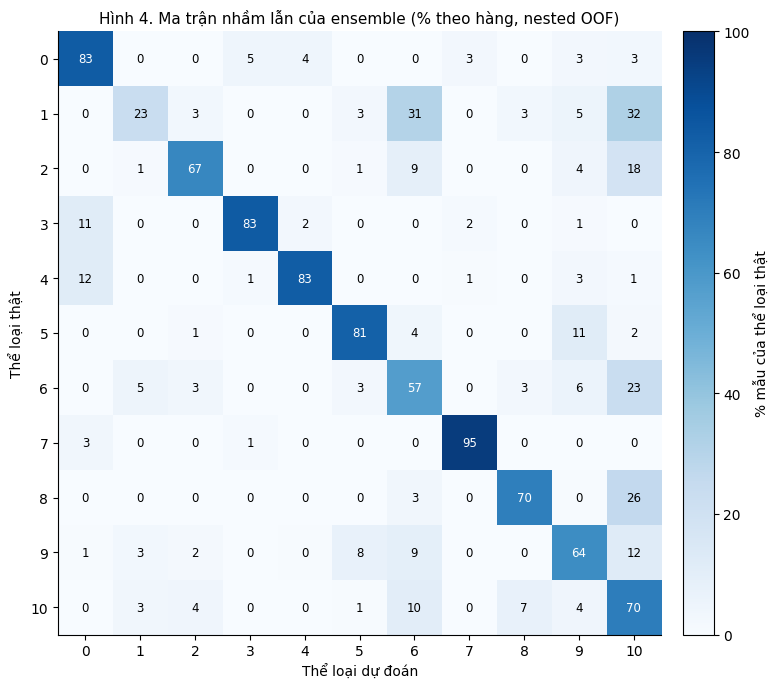

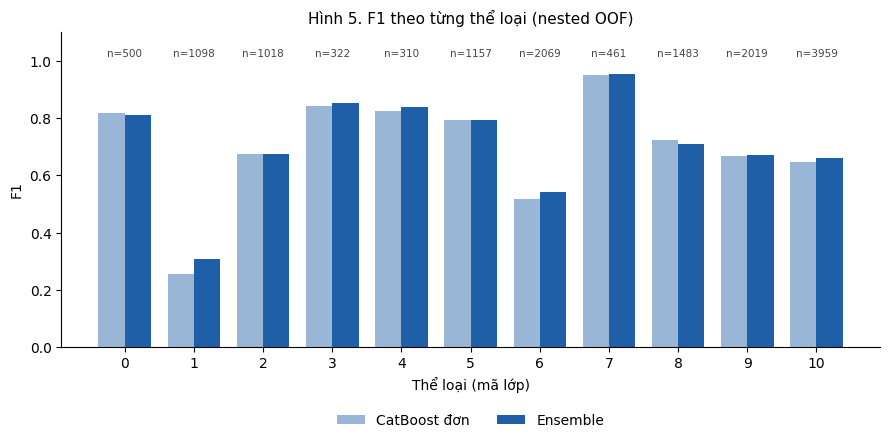

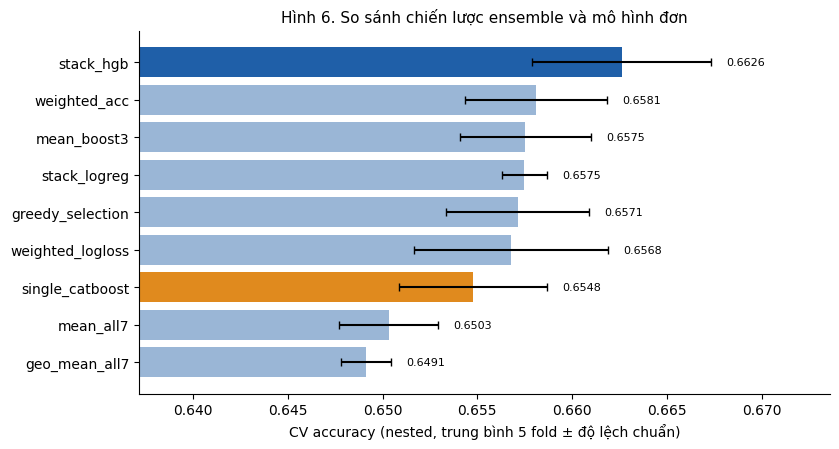

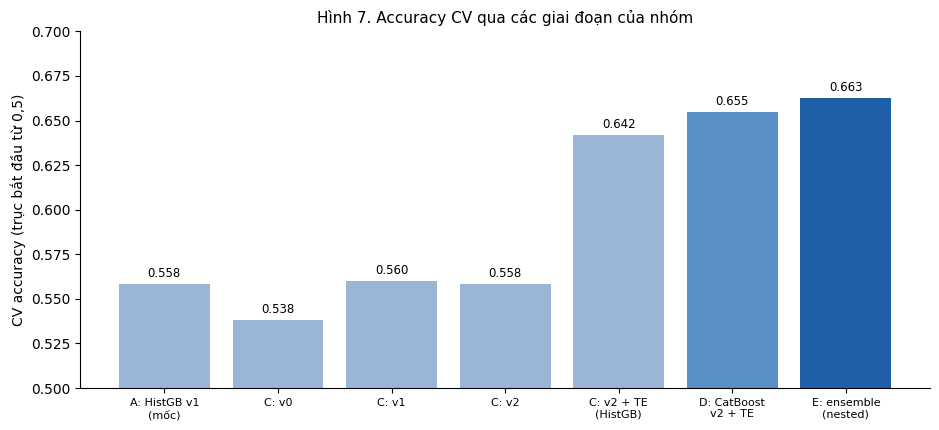

In [9]:
# Hình 4: ma trận nhầm lẫn chuẩn hóa theo hàng
fig, ax = plt.subplots(figsize=(8.2, 7))
im = ax.imshow(cmn * 100, cmap="Blues", vmin=0, vmax=100)
for i in range(K):
    for j in range(K):
        v = cmn[i, j] * 100
        ax.text(j, i, f"{v:.0f}", ha="center", va="center", fontsize=8.5,
                color="white" if v > 55 else "black")
ax.set_xticks(range(K)); ax.set_yticks(range(K))
ax.set_xlabel("Thể loại dự đoán"); ax.set_ylabel("Thể loại thật")
ax.set_title("Hình 4. Ma trận nhầm lẫn của ensemble (% theo hàng, nested OOF)", fontsize=11)
cb = fig.colorbar(im, ax=ax, fraction=0.046, pad=0.03); cb.set_label("% mẫu của thể loại thật")
fig.tight_layout(); fig.savefig(OUT_FIG / "E_04_confusion_matrix.png"); plt.show()

# Hình 5: F1 theo từng thể loại, ensemble so với CatBoost đơn
fig, ax = plt.subplots(figsize=(9, 4.6))
x = np.arange(K); w = 0.38
ax.bar(x - w / 2, f_s, w, label="CatBoost đơn", color="#9ab6d6")
ax.bar(x + w / 2, f1, w, label="Ensemble", color="#1f5fa8")
for xi, s_ in zip(x, sup):
    ax.text(xi, 1.015, f"n={s_}", ha="center", fontsize=7.5, color="#444")
ax.set_xticks(x); ax.set_ylim(0, 1.1); ax.set_xlabel("Thể loại (mã lớp)"); ax.set_ylabel("F1")
ax.set_title("Hình 5. F1 theo từng thể loại (nested OOF)", fontsize=11)
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.17), ncol=2, frameon=False)
fig.tight_layout(); fig.savefig(OUT_FIG / "E_05_f1_per_class.png", bbox_inches="tight"); plt.show()

# Hình 6: so sánh các chiến lược (nested accuracy ± std giữa fold)
d6 = cmp_df.sort_values("nested_acc")
fig, ax = plt.subplots(figsize=(8.5, 4.6))
colors = ["#1f5fa8" if s_ == FINAL else ("#e08a1e" if s_ == "single_catboost" else "#9ab6d6")
          for s_ in d6.strategy]
ax.barh(d6.strategy, d6.nested_acc, xerr=d6.nested_std, color=colors, capsize=3)
for yi, (a, s_) in enumerate(zip(d6.nested_acc, d6.nested_std)):
    ax.text(a + s_ + 0.0008, yi, f"{a:.4f}", va="center", fontsize=8)
lo = d6.nested_acc.min() - 0.012
ax.set_xlim(lo, d6.nested_acc.max() + 0.011); ax.set_xlabel("CV accuracy (nested, trung bình 5 fold ± độ lệch chuẩn)")
ax.set_title("Hình 6. So sánh chiến lược ensemble và mô hình đơn", fontsize=11)
fig.tight_layout(); fig.savefig(OUT_FIG / "E_06_ensemble_comparison.png"); plt.show()

# Hình 7: tiến trình CV qua các giai đoạn (số lấy từ các file của A, C, D, E)
ablC = pd.read_csv(EV / "cv_logs" / "ablation_foldsafe_C.csv").set_index("Version")["Accuracy"]
steps = [("A: HistGB v1\n(mốc)", 0.5585), ("C: v0", ablC["v0"]), ("C: v1", ablC["v1"]), ("C: v2", ablC["v2"]),
         ("C: v2 + TE\n(HistGB)", ablC["v2+TE"]), ("D: CatBoost\nv2 + TE", float(base_df.loc[0, "cv_accuracy"])),
         ("E: ensemble\n(nested)", float(cmp_df.set_index("strategy").loc[FINAL, "nested_acc"]))]
fig, ax = plt.subplots(figsize=(9.5, 4.4))
cols = ["#9ab6d6"] * 5 + ["#5b8fc7", "#1f5fa8"]
ax.bar(range(len(steps)), [s_[1] for s_ in steps], color=cols)
for i, (_, v) in enumerate(steps):
    ax.text(i, v + 0.004, f"{v:.3f}", ha="center", fontsize=8.5)
ax.set_xticks(range(len(steps))); ax.set_xticklabels([s_[0] for s_ in steps], fontsize=8)
ax.set_ylim(0.5, 0.7); ax.set_ylabel("CV accuracy (trục bắt đầu từ 0,5)")
ax.set_title("Hình 7. Accuracy CV qua các giai đoạn của nhóm", fontsize=11)
fig.tight_layout(); fig.savefig(OUT_FIG / "E_07_cv_progress.png"); plt.show()

## 9. Xuất bài nộp, lưu OOF/test của ensemble và Bảng 3

In [10]:
test_proba = final_pred(PT)
assert test_proba.shape == (len(test_ids), K) and np.isfinite(test_proba).all()
sub = pd.DataFrame({"Id": test_ids, "Class": classes[test_proba.argmax(1)]})
assert len(sub) == 3600 and sub.Id.is_unique and sub.Class.between(0, K - 1).all()
SUB_NAME = "ensemble_E.csv"
sub.to_csv(OUT_SUB / SUB_NAME, index=False)
share = pd.DataFrame({"train_share": np.bincount(y, minlength=K) / n,
                      "oof_pred_share": np.bincount(yp, minlength=K) / n,
                      "test_pred_share": np.bincount(sub.Class, minlength=K) / len(sub)}).round(4)
print(f"Đã ghi {OUT_SUB / SUB_NAME} ({len(sub)} dòng, cột Id,Class)")
print(share.to_string())
share.to_csv(OUT_EV / "class_share_check_E.csv")

TAG_OUT = f"ensemble_{FINAL}_E"
fa_final = fold_accs(final_nested)
np.save(OUT_CV / f"{TAG_OUT}_oof.npy", final_nested)
np.save(OUT_CV / f"{TAG_OUT}_test.npy", test_proba)
(OUT_CV / f"{TAG_OUT}_cv.json").write_text(json.dumps({
    "name": TAG_OUT, "metric": "accuracy", "cv_mean": float(np.mean(fa_final)), "cv_std": float(np.std(fa_final)),
    "macro_f1": float(f1.mean()), "fold_scores": fa_final, "seconds": 0.0, "seed": SEED, "n_folds": N_FOLDS,
    "note": "OOF là nested (trọng số/meta học trên 4 fold, dự đoán fold còn lại); test = ensemble học trên toàn bộ OOF "
            "áp lên xác suất test (trung bình 5 outer model của D)."}, indent=2), encoding="utf-8")

(OUT_EV / "final_ensemble_E.json").write_text(json.dumps(
    {"final_strategy": FINAL, "description": STRATEGIES[FINAL][0], "info": final_pred.info,
     "models_order": SHORT, "tags": TAGS, "submission_file": f"submissions/{SUB_NAME}",
     "cv_tag": TAG_OUT, "nested_accuracy": float(np.mean(fa_final)), "nested_std": float(np.std(fa_final)),
     "macro_f1": float(f1.mean()), "oracle_accuracy_7_models": oracle}, indent=2, default=str), encoding="utf-8")

# Bảng 3 (markdown) sinh tự động từ số liệu thật để tránh gõ lại sai
lines = ["# Bảng 3. So sánh CV accuracy các mô hình và ensemble — E", "",
         "Accuracy là trung bình 5 fold (StratifiedKFold seed 42); std là độ lệch chuẩn giữa 5 fold. "
         "Với ensemble, điểm là **nested** (trọng số/meta-learner học trên 4 fold, chấm trên fold còn lại).", "",
         "| Mô hình / chiến lược | CV accuracy | Std | Macro F1 | Log-loss |", "|---|---:|---:|---:|---:|"]
for _, r in base_df.sort_values("cv_accuracy", ascending=False).iterrows():
    lines.append(f"| {r.model} (đơn) | {r.cv_accuracy:.4f} | {r.cv_std:.4f} | {r.macro_f1:.4f} | {r.log_loss:.4f} |")
for _, r in cmp_df[cmp_df.strategy != "single_catboost"].sort_values("nested_acc", ascending=False).iterrows():
    b = "**" if r.strategy == FINAL else ""
    lines.append(f"| {b}Ensemble: {r['mô tả']}{b} | {b}{r.nested_acc:.4f}{b} | {r.nested_std:.4f} | "
                 f"{r.macro_f1:.4f} | {r.log_loss:.4f} |")
lines += ["", f"Mốc baseline của A (HistGB v1): 0,5585. Oracle (ít nhất một trong 7 mô hình nền đúng): {oracle:.4f}."]
(OUT_PAPER / "table_03_cv_results_E.md").write_text("\n".join(lines) + "\n", encoding="utf-8")
print("\n".join(lines))

# Bảng tổng hợp một file để dán vào báo cáo / poster
summary = {"final_strategy": FINAL, "nested_accuracy": float(np.mean(fa_final)), "nested_std": float(np.std(fa_final)),
           "best_single_accuracy": float(base_df.loc[0, "cv_accuracy"]), "diff_vs_single": diff,
           "macro_f1": float(f1.mean()), "oracle": oracle, "bootstrap_ci95": boot["bootstrap_ci95"],
           "mcnemar_p": boot["mcnemar_p"]}
(OUT_EV / "summary_E.json").write_text(json.dumps(summary, indent=2), encoding="utf-8")
print(json.dumps(summary, indent=2))

Đã ghi E:\MLGroup\Music Genre Classification\submissions\ensemble_E.csv (3600 dòng, cột Id,Class)
    train_share  oof_pred_share  test_pred_share
0        0.0347          0.0364           0.0383
1        0.0763          0.0388           0.0436
2        0.0707          0.0691           0.0683
3        0.0224          0.0213           0.0217
4        0.0215          0.0209           0.0217
5        0.0804          0.0839           0.0822
6        0.1437          0.1599           0.1619
7        0.0320          0.0319           0.0303
8        0.1030          0.0985           0.0986
9        0.1402          0.1291           0.1233
10       0.2750          0.3102           0.3100
# Bảng 3. So sánh CV accuracy các mô hình và ensemble — E

Accuracy là trung bình 5 fold (StratifiedKFold seed 42); std là độ lệch chuẩn giữa 5 fold. Với ensemble, điểm là **nested** (trọng số/meta-learner học trên 4 fold, chấm trên fold còn lại).

| Mô hình / chiến lược | CV accuracy | Std | Macro F1 | Log-loss 

## 10. Kiểm tra độ bền của lựa chọn

Ba điều cần kiểm tra trước khi tin vào ensemble chốt:
1. Xác suất test là trung bình của 5 outer model nên có thể khác phân phối so với OOF (mỗi dòng OOF chỉ do 1 model dự đoán).
   Meta-learner học trên OOF nên cần xem sự lệch này có đáng kể không.
2. Ensemble chốt có thật sự hơn các ensemble đơn giản hơn, hay chỉ do chọn trong nhiều ứng viên (winner's curse).
3. Các bài nộp từ các ensemble khác nhau có khác nhau nhiều trên test hay không.

In [11]:
rob = {}
conf_oof = P.max(2).mean(1)            # độ tự tin trung bình (max prob) từng mô hình trên OOF
conf_test = PT.max(2).mean(1)
rob["mean_max_prob_oof_vs_test"] = {s_: [float(a), float(b)] for s_, a, b in zip(SHORT, conf_oof, conf_test)}
print(pd.DataFrame({"oof": conf_oof, "test": conf_test, "test-oof": conf_test - conf_oof}, index=SHORT).round(4))

# 2. so sánh có ghép cặp giữa ensemble chốt và các ứng viên đơn giản
def _paired(a_key, b_key):
    oa = nested_store[a_key].argmax(1) == y
    ob = nested_store[b_key].argmax(1) == y
    d = np.array([(oa[i].mean() - ob[i].mean()) for i in (np.random.default_rng(SEED).integers(0, n, (3000, n)))])
    fd = [float(np.mean(oa[fold_ids == k]) - np.mean(ob[fold_ids == k])) for k in range(N_FOLDS)]
    return {"diff": float(oa.mean() - ob.mean()), "ci95": [float(np.percentile(d, 2.5)), float(np.percentile(d, 97.5))],
            "fold_diffs": fd, "folds_ensemble_better": int(sum(x > 0 for x in fd))}

rob["final_vs_simpler"] = {k: _paired(FINAL, k) for k in ["mean_boost3", "stack_logreg", "weighted_acc",
                                                            "weighted_logloss"] if k != FINAL}
print(json.dumps(rob["final_vs_simpler"], indent=1))

# 3. mức bất đồng trên test giữa các ensemble, so với mức bất đồng trên OOF
keys = [k for k in ["stack_hgb", "stack_logreg", "weighted_acc", "mean_boost3"] if k in full_preds]
dd = {}
for a_i, a in enumerate(keys):
    for b in keys[a_i + 1:]:
        d_test = float(np.mean(full_preds[a](PT).argmax(1) != full_preds[b](PT).argmax(1)))
        d_oof = float(np.mean(nested_store[a].argmax(1) != nested_store[b].argmax(1)))
        dd[f"{a} vs {b}"] = {"disagree_oof": d_oof, "disagree_test": d_test}
rob["ensemble_disagreement"] = dd
print(pd.DataFrame(dd).T.round(4))
(OUT_EV / "robustness_E.json").write_text(json.dumps(rob, indent=2), encoding="utf-8")

               oof    test  test-oof
CatBoost    0.6496  0.6408   -0.0088
LightGBM    0.6607  0.6486   -0.0121
XGBoost     0.6434  0.6318   -0.0116
HistGB      0.6830  0.6609   -0.0220
MLP         0.6434  0.6357   -0.0077
SVM         0.6403  0.6322   -0.0081
ExtraTrees  0.5414  0.5322   -0.0092
{
 "mean_boost3": {
  "diff": 0.0050708530147263176,
  "ci95": [
   0.0006234370658515848,
   0.009657196443456504
  ],
  "fold_diffs": [
   0.009027777777777746,
   0.004168113928447403,
   0.0024313997915942354,
   0.00590482806530046,
   0.003820771101076814
  ],
  "folds_ensemble_better": 5
 },
 "stack_logreg": {
  "diff": 0.005140316754654095,
  "ci95": [
   0.0008318282856348092,
   0.009794387329813858
  ],
  "fold_diffs": [
   0.011111111111111072,
   0.008336227856894807,
   -0.002084056964223757,
   0.003820771101076703,
   0.0045154567558179926
  ],
  "folds_ensemble_better": 4
 },
 "weighted_acc": {
  "diff": 0.004515143095304319,
  "ci95": [
   0.0,
   0.009030286190608527
  ],
  "f

2837